# Câu c: Vẽ biểu đồ so sánh thời gian xử lý hai thuật toán

Phần 2 – Bài 6 (trang 45): Groceries – 9.835 giao dịch, 169 mặt hàng.

**Về khoảng min_sup 0.01% – 0.1%:** với 9.835 giao dịch, min_sup = 0.01% tương đương support count ≥ 1, tức là *mọi* tập con của *mọi* giao dịch đều phổ biến (giao dịch dài nhất có 32 mặt hàng → tới 2³² tập con), nên không thuật toán nào chạy hết được. Thử thực tế trên máy 8 GB RAM: Apriori bị tràn bộ nhớ từ min_sup = 0.04% trở xuống. Vì vậy bài này khảo sát **min_sup từ 0.1% giảm dần tới 0.05%** (bước 0.01%) cho cả hai thuật toán, và chạy thêm FP-Growth ở 0.04%, 0.03%, 0.02% để thấy FP-Growth vẫn xử lý được khi Apriori đã không chạy nổi.

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
# Mỗi dòng là một giao dịch, các mặt hàng cách nhau bởi dấu phẩy (số mặt hàng mỗi dòng khác nhau)
with open(DATA + 'groceries.csv', encoding='utf-8') as f:
    transactions = [line.strip().split(',') for line in f if line.strip()]

te = TransactionEncoder()
df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

SUPPORTS = [0.001, 0.0009, 0.0008, 0.0007, 0.0006, 0.0005]   # 0.1% -> 0.05%
SUPPORTS_FP_EXTRA = [0.0004, 0.0003, 0.0002]                 # chỉ FP-Growth chạy được

res_ap = []
for s in SUPPORTS:
    t0 = time.perf_counter()
    fi = apriori(df, min_support=s, use_colnames=True)
    res_ap.append({'min_sup (%)': s * 100, 'số tập phổ biến': len(fi), 'thời gian Apriori (s)': round(time.perf_counter() - t0, 3)})
res_ap = pd.DataFrame(res_ap)

res_fp = []
for s in SUPPORTS + SUPPORTS_FP_EXTRA:
    t0 = time.perf_counter()
    fi = fpgrowth(df, min_support=s, use_colnames=True)
    res_fp.append({'min_sup (%)': s * 100, 'số tập phổ biến': len(fi), 'thời gian FP-Growth (s)': round(time.perf_counter() - t0, 3)})
res_fp = pd.DataFrame(res_fp)

---
## Thực hiện yêu cầu

In [4]:
print(SV)
cmp = res_fp.merge(res_ap, on=['min_sup (%)', 'số tập phổ biến'], how='left')
cmp['Apriori / FP-Growth'] = (cmp['thời gian Apriori (s)'] / cmp['thời gian FP-Growth (s)']).round(1)
cmp

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


,min_sup (%),số tập phổ biến,thời gian FP-Growth (s),thời gian Apriori (s),Apriori / FP-Growth
0,0.10,13492,0.488,1.594,3.3
1,0.09,16188,0.600,1.708,2.8
2,0.08,19979,0.559,2.000,3.6
3,0.07,25570,0.634,2.580,4.1
4,0.06,34353,0.934,3.493,3.7
5,0.05,49580,1.017,5.737,5.6
6,0.04,80388,1.241,NaN,NaN
7,0.03,166682,1.901,NaN,NaN
8,0.02,790072,5.686,NaN,NaN


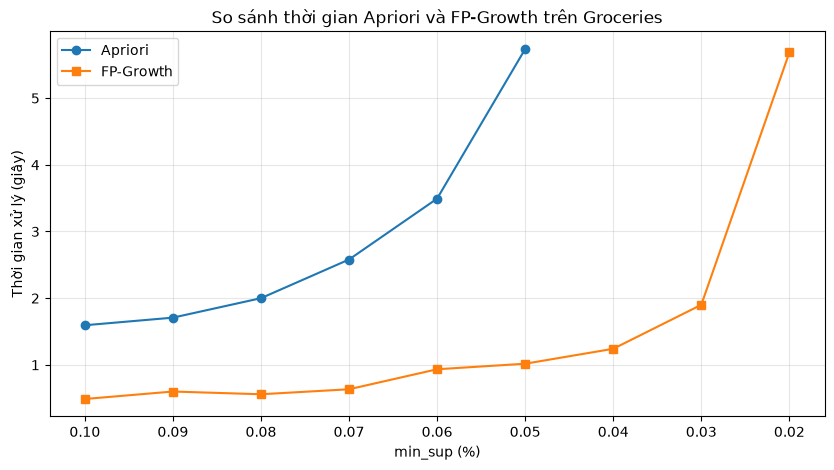

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(res_ap['min_sup (%)'], res_ap['thời gian Apriori (s)'], 'o-', label='Apriori')
ax.plot(res_fp['min_sup (%)'], res_fp['thời gian FP-Growth (s)'], 's-', label='FP-Growth')
ax.invert_xaxis()   # min_sup giảm dần từ trái sang phải
ax.set_xlabel('min_sup (%)')
ax.set_ylabel('Thời gian xử lý (giây)')
ax.set_title('So sánh thời gian Apriori và FP-Growth trên Groceries')
ax.legend()
ax.grid(alpha=.3)
plt.show()

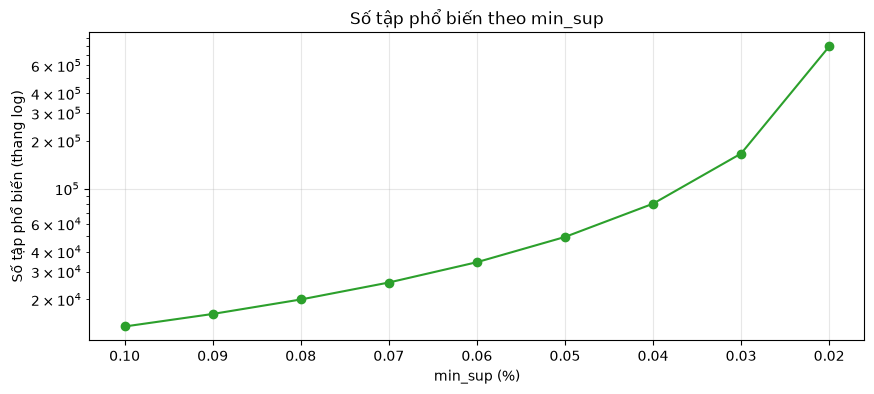

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(res_fp['min_sup (%)'], res_fp['số tập phổ biến'], 'o-', color='tab:green')
ax.invert_xaxis()
ax.set_yscale('log')
ax.set_xlabel('min_sup (%)')
ax.set_ylabel('Số tập phổ biến (thang log)')
ax.set_title('Số tập phổ biến theo min_sup')
ax.grid(alpha=.3)
plt.show()

**Nhận xét:**

- Hai thuật toán cho cùng số tập phổ biến ở mọi mức min_sup, nhưng thời gian khác nhau rõ: FP-Growth nhanh hơn Apriori khoảng 3–6 lần, và khoảng cách càng lớn khi min_sup càng nhỏ.
- Thời gian Apriori tăng nhanh gần theo số tập phổ biến, còn FP-Growth tăng chậm hơn nhiều. Từ 0,04% trở xuống Apriori bị tràn bộ nhớ, trong khi FP-Growth vẫn chạy được tới 0,02%.

**Giải thích:**
- **Apriori** sinh ứng viên theo từng mức (C1 → L1 → C2 → L2 → …) và phải quét lại toàn bộ dữ liệu ở mỗi mức để đếm support. Khi min_sup nhỏ, số ứng viên tăng theo cấp số nhân (một tập phổ biến 7 phần tử kéo theo 2⁷ − 1 = 127 tập con cũng phổ biến), nên tốn nhiều thời gian và bộ nhớ để lưu và đếm ứng viên.
- **FP-Growth** chỉ quét dữ liệu 2 lần để nén toàn bộ giao dịch vào cây FP (các giao dịch có chung tiền tố dùng chung nhánh), sau đó khai thác đệ quy trên các cây FP điều kiện, **không sinh ứng viên**. Vì vậy chi phí chủ yếu phụ thuộc vào kích thước cây, không bùng nổ theo số ứng viên.
- Khi min_sup lớn và có ít tập phổ biến (như Online Retail với min_sup = 3%), hai thuật toán chạy nhanh như nhau, thậm chí Apriori có thể nhanh hơn vì không tốn chi phí dựng cây. Khi min_sup nhỏ, dữ liệu có nhiều tập phổ biến dài thì FP-Growth vượt trội.